In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings. filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print("✅ Đã import toàn bộ thư viện thành công!")

✅ Đã import toàn bộ thư viện thành công!


In [48]:
# Đọc file dữ liệu F1 thực tế
df = pd.read_csv('data.f1.csv')

# XÓA CÁC DÒNG BỊ TRỐNG CỘT MỤC TIÊU (is_podium)
df = df.dropna(subset=['is_podium'])

print("--- THÔNG TIN CHI TIẾT TỆP DỮ LIỆU ---")
df.info()

print("\n--- 5 DÒNG DỮ LIỆU ĐẦU TIÊN ---")
display(df.head())

--- THÔNG TIN CHI TIẾT TỆP DỮ LIỆU ---
<class 'pandas.core.frame.DataFrame'>
Index: 65812 entries, 0 to 65811
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   season             65812 non-null  int64  
 1   round              65812 non-null  float64
 2   circuit            65812 non-null  object 
 3   constructor        65812 non-null  object 
 4   grid               65812 non-null  float64
 5   pit_stops          65812 non-null  float64
 6   driver_experience  65812 non-null  float64
 7   is_podium          65812 non-null  float64
dtypes: float64(5), int64(1), object(2)
memory usage: 4.5+ MB

--- 5 DÒNG DỮ LIỆU ĐẦU TIÊN ---


,season,round,circuit,constructor,grid,pit_stops,driver_experience,is_podium
0,2024,20.0,Monaco,Mercedes,9.0,2.0,6.0,0.0
1,2021,17.0,Spa,Mercedes,11.0,3.0,13.0,1.0
2,2025,21.0,Monza,Ferrari,7.0,3.0,3.0,0.0
3,2022,4.0,Miami,Mercedes,5.0,1.0,5.0,0.0
4,2024,22.0,Miami,Alpine,2.0,2.0,12.0,0.0


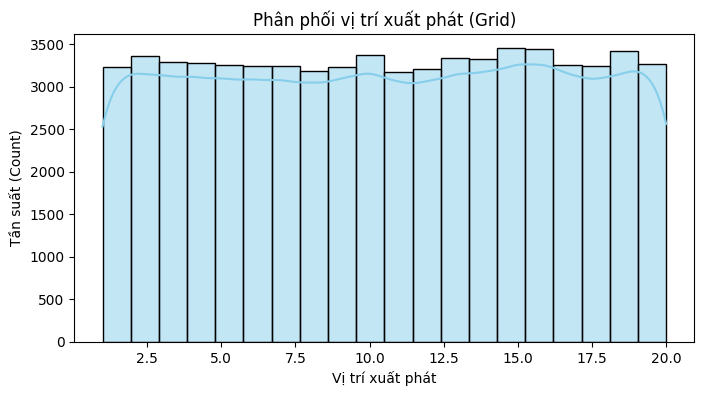

In [49]:
# Trực quan hóa phân phối vị trí xuất phát (Grid)
plt.figure(figsize=(8, 4))
sns.histplot(df['grid'], kde=True, color='skyblue', bins=20)
plt.title('Phân phối vị trí xuất phát (Grid)')
plt.xlabel('Vị trí xuất phát')
plt.ylabel('Tần suất (Count)')
plt.show()

In [50]:
# Tách X và y (Dữ liệu đã có sẵn cột 'is_podium' từ file CSV)
X = df.drop('is_podium', axis=1)
y = df['is_podium']

# Chia tỷ lệ tập Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(f"📊 Kích thước tập học (Train): {X_train.shape[0]:,} dòng")
print(f"📊 Kích thước tập kiểm tra (Test): {X_test.shape[0]:,} dòng")

📊 Kích thước tập học (Train): 52,649 dòng
📊 Kích thước tập kiểm tra (Test): 13,163 dòng


In [51]:
# Phân loại cột số và cột chữ có trong data.f1.csv
num_features = ['season', 'round', 'grid', 'pit_stops', 'driver_experience']
cat_features = ['circuit', 'constructor']

# Pipeline cho cột số: Nếu thiếu giá trị -> Điền số trung vị (median), sau đó chuẩn hóa (scaler)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline cho cột chữ: Nếu thiếu giá trị -> Điền chữ 'Unknown', sau đó mã hóa (OneHotEncoder)
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Cấu hình bộ tiền xử lý tổng hợp (Kết hợp làm sạch + xử lý)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("✅ Tiền xử lý dữ liệu hoàn tất!")

✅ Tiền xử lý dữ liệu hoàn tất!


In [52]:
model = LogisticRegression(max_iter=1000)

print("\n🤖 Bắt đầu huấn luyện mô hình...")
model.fit(X_train_processed, y_train)
print("✅ Huấn luyện mô hình thành công!")


🤖 Bắt đầu huấn luyện mô hình...
✅ Huấn luyện mô hình thành công!



🏆 ĐỘ CHÍNH XÁC TỔNG QUAN (Accuracy): 84.84%

--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---
              precision    recall  f1-score   support

 Không cúp ❌       0.85      1.00      0.92     11168
    Có cúp 🏆       0.00      0.00      0.00      1995

    accuracy                           0.85     13163
   macro avg       0.42      0.50      0.46     13163
weighted avg       0.72      0.85      0.78     13163



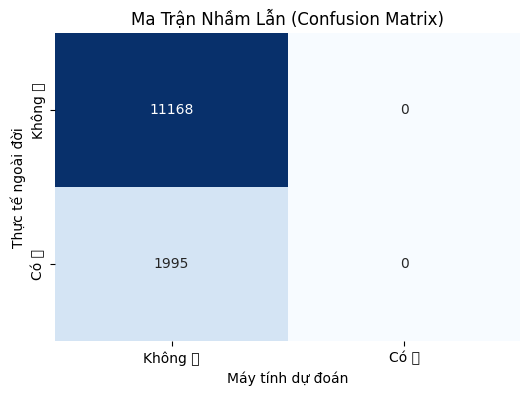

In [53]:
# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test_processed)

# Tính độ chính xác
accuracy = accuracy_score(y_test, y_pred) * 100
print(f"\n🏆 ĐỘ CHÍNH XÁC TỔNG QUAN (Accuracy): {accuracy:.2f}%\n")

# Báo cáo phân loại chi tiết
print("--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---")
print(classification_report(y_test, y_pred, target_names=[
      'Không cúp ❌', 'Có cúp 🏆']))

# Vẽ biểu đồ ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Không ❌', 'Có 🏆'],
            yticklabels=['Không ❌', 'Có 🏆'])
plt.title('Ma Trận Nhầm Lẫn (Confusion Matrix)')
plt.xlabel('Máy tính dự đoán')
plt.ylabel('Thực tế ngoài đời')
plt.show()
